# Hazen-Williams vs Darcy-Weisbach

Exploration notebook for Phase 1. All calculations call `wdtk.headloss`; nothing here is reused elsewhere.

**Question:** if a Hazen-Williams C is chosen so that HW and DW agree at one design point, how far apart do they drift across the range of diameters and velocities found in distribution systems?

Matching the two formulas at one point avoids assuming a correspondence between a C-factor and a roughness height. The only physical inputs are the water temperature (viscosity from the project's sourced property table) and an assumed roughness height.

The figures are produced by the same functions as `scripts/phase1_headloss_figures.py` (`wdtk.headloss_comparison`, `wdtk.plotting`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from wdtk import fluid, plotting
from wdtk import headloss as hl
from wdtk.headloss_comparison import equivalent_c, ratio_grid

plotting.apply_style()

## Inputs

| Input | Value | Status |
|---|---|---|
| Water temperature | 20 °C | design condition (assumption) |
| Kinematic viscosity | from `wdtk.fluid` at 20 °C | sourced table |
| Absolute roughness ε | 0.1 mm | assumption: representative of cement-lined ductile iron (project author) |
| Calibration point | D = 300 mm, V = 1.0 m/s | assumption |
| Length | 1000 m | both formulas are linear in L, so the ratio does not depend on it |

In [2]:
TEMPERATURE_C = 20.0
NU_M2S = fluid.kinematic_viscosity_m2s(TEMPERATURE_C)
EPS_M = 0.1e-3
CALIBRATION = (0.300, 1.0)  # D (m), V (m/s)

grid = ratio_grid(
    np.geomspace(0.05, 1.2, 90), np.linspace(0.3, 3.0, 90), EPS_M, NU_M2S, CALIBRATION
)
print(f"nu at {TEMPERATURE_C:g} C = {NU_M2S:.4e} m2/s")
print(
    f"Re at calibration point = {hl.reynolds_number(CALIBRATION[1], CALIBRATION[0], NU_M2S):,.0f}"
)
print(f"Calibrated Hazen-Williams C = {grid.c_calibrated:.1f}")

nu at 20 C = 1.0022e-06 m2/s
Re at calibration point = 299,329
Calibrated Hazen-Williams C = 140.7


## Ratio of predicted head loss across diameter and velocity

h_HW / h_DW over the grid: min 0.801, max 1.096


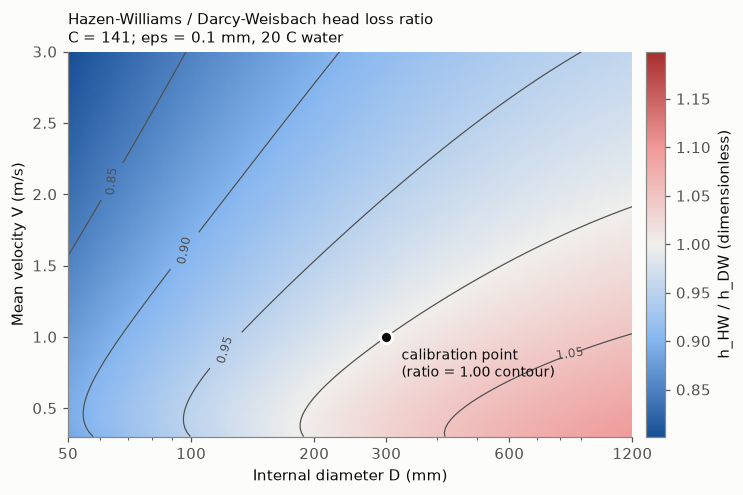

In [3]:
r = grid.ratio
print(f"h_HW / h_DW over the grid: min {r.min():.3f}, max {r.max():.3f}")
fig, ax = plt.subplots(figsize=(7.0, 4.6))
plotting.plot_hw_dw_ratio(
    ax,
    grid,
    CALIBRATION,
    f"C = {grid.c_calibrated:.0f}; eps = {EPS_M * 1000:g} mm, {TEMPERATURE_C:g} C water",
)
fig.tight_layout()
plt.show()

## Equivalent C: what C would make Hazen-Williams match Darcy-Weisbach?

For each condition, compute the DW head loss and back-calculate the C that reproduces it (`hazen_williams_c_factor`). If HW were physically exact, this would be a constant for a given pipe.

diameter  D = 100 mm      : C from  129.0 to  137.1
diameter  D = 300 mm      : C from  133.8 to  143.0
diameter  D = 900 mm      : C from  136.8 to  147.0
roughness eps = 0 (smooth): C from  149.3 to  157.4
roughness eps = 0.1 mm    : C from  133.8 to  143.0
roughness eps = 1 mm      : C from  100.8 to  118.3


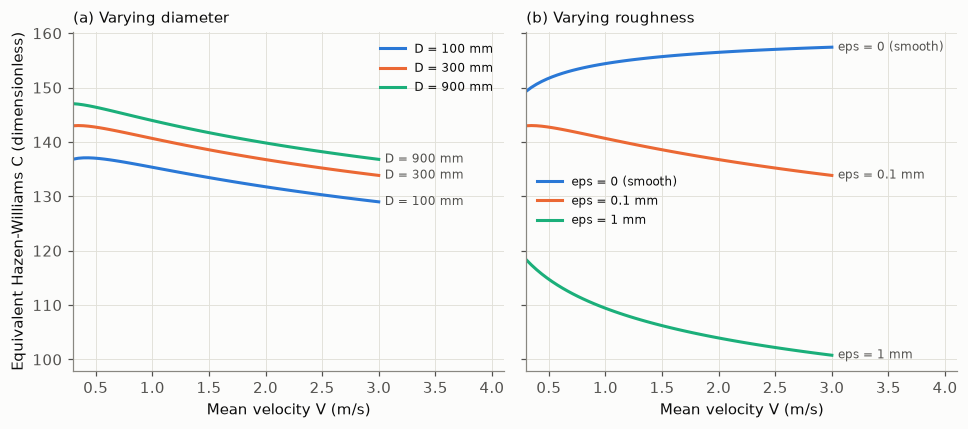

In [4]:
v = np.linspace(0.3, 3.0, 60)
by_d = {f"D = {d * 1000:.0f} mm": equivalent_c(v, d, EPS_M, NU_M2S) for d in (0.1, 0.3, 0.9)}
by_eps = {
    lab: equivalent_c(v, CALIBRATION[0], e, NU_M2S)
    for lab, e in (("eps = 0 (smooth)", 0.0), ("eps = 0.1 mm", 1e-4), ("eps = 1 mm", 1e-3))
}
for name, group in (("diameter", by_d), ("roughness", by_eps)):
    for lab, c in group.items():
        print(f"{name:9s} {lab:16s}: C from {c.min():6.1f} to {c.max():6.1f}")
fig, axes = plt.subplots(1, 2, figsize=(9.0, 4.0), sharey=True)
plotting.plot_equivalent_c(
    axes, v, [("(a) Varying diameter", by_d), ("(b) Varying roughness", by_eps)]
)
fig.tight_layout()
plt.show()

## Interpretation (for the inputs above)

**What the figures show**

- With C calibrated to match at 300 mm and 1 m/s, the two formulas stay within about ±5% over a band of diameters and velocities around that point. Away from it they diverge. Hazen-Williams predicts about 20% *less* loss than Darcy-Weisbach at 50 mm and 3 m/s, and about 10% *more* at 1200 mm and 0.3 m/s.
- The C that reproduces Darcy-Weisbach is not a constant of the pipe. For the same pipe it shifts by roughly 8 to 17 units across 0.3 to 3 m/s, and it changes with diameter at a fixed roughness height.
- The trend reverses with roughness. For a smooth pipe the equivalent C *rises* with velocity; for a rough pipe it *falls*.

**Why**

Hazen-Williams fixes the velocity exponent at 1/0.54 ≈ 1.85 and has no viscosity term. In Darcy-Weisbach the exponent depends on the flow regime. In smooth-pipe turbulence f falls as Re rises, so head loss grows more slowly than V². In fully rough flow f is constant and head loss grows as V². Hazen-Williams matches only the regime in between. With one fixed C it cannot follow a pipe across a wide range of Re or relative roughness.

**When to use each**

- **Hazen-Williams** suits water at ordinary temperatures, in turbulent flow, in the pipe sizes and velocities typical of distribution systems. Within that range a calibrated C works well. It is the convention in US water distribution practice and the EPANET default, so models built to that convention should use it.
- **Darcy-Weisbach** is physically based and dimensionally consistent. Use it for other fluids or temperatures, for laminar or transitional flow, for very small or very large pipes, for high velocities, and for very smooth or very rough pipes. It is also the right choice whenever head loss must be extrapolated beyond the conditions where a C-factor was calibrated.
- **In either case:** C or ε for an existing main should come from field testing (fire-flow or C-factor tests) where possible, because both describe a pipe's condition, not just its material.